# 03 — Modèle de classification de l'étiquette DPE

**Objectif** : prédire l'étiquette DPE (A à G) à partir des caractéristiques du logement retenues dans le notebook `02`, et mesurer honnêtement la qualité du modèle.

**Démarche**
1. Comparer plusieurs modèles par **validation croisée groupée par adresse** sur le train (aucune adresse n'est à la fois dans l'entraînement et la validation d'un même pli).
2. Régler légèrement le meilleur modèle.
3. L'évaluer **une seule fois** sur le test, avec un intervalle d'incertitude.
4. Analyser les erreurs.
5. Tester des variantes (variables, copies exactes) **par validation croisée sur le train**, jamais sur le test.
6. Enregistrer le pipeline complet (préprocesseur + modèle).

**Règle** : le test n'est utilisé qu'à la section 5. Toutes les décisions (choix du modèle, réglages, variantes) se prennent sur le train.

## 0. Préparation

In [3]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, make_scorer)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

from src.utilis import config
from src.data import transformateurs as tf

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (9, 4.5)

DOSSIER_FIG = config.RACINE / "reports" / "figures"
ETIQ, CONSO = config.CIBLE_CLASSIFICATION, config.CIBLE_REGRESSION
ORDRE = config.ORDRE_ETIQUETTES
GRAINE = config.GRAINE_ALEATOIRE

N_PLIS = 5            # plis de la validation croisée
REGLER = True         # réglage léger des hyperparamètres du meilleur modèle
N_BOOTSTRAP = 300     # rééchantillonnages pour l'intervalle d'incertitude


def sauver(fig, nom):
    DOSSIER_FIG.mkdir(parents=True, exist_ok=True)
    fig.savefig(DOSSIER_FIG / f"{nom}.png", dpi=150, bbox_inches="tight")

## 1. Chargement et contrôles

In [4]:
train = pd.read_csv(config.DATA_TRAITE / "train.csv", low_memory=False)
test = pd.read_csv(config.DATA_TRAITE / "test.csv", low_memory=False)
with open(config.DOSSIER_MODELES / "variables_retenues.json", encoding="utf-8") as f:
    decisions = json.load(f)

VAR_NUM = decisions["variables_numeriques"]
VAR_CAT = decisions["variables_categorielles"]
VARIABLES = VAR_NUM + VAR_CAT

# Même regroupement par adresse que dans le notebook 02.
for d in (train, test):
    d["groupe"] = d["adresse_ban"].fillna(d["numero_dpe"])

assert not set(train["groupe"]) & set(test["groupe"]), "des adresses sont dans le train ET le test"
assert not [v for v in VARIABLES if config.est_colonne_fuite(v)], "colonne issue du calcul du DPE"
assert train[ETIQ].notna().all() and test[ETIQ].notna().all()

print(f"train : {len(train):,} lignes | test : {len(test):,} lignes")
print(f"{len(VARIABLES)} variables : {len(VAR_NUM)} numériques, {len(VAR_CAT)} catégorielles")
print(VARIABLES)
print("\nÉtiquettes du train (%) :")
print((train[ETIQ].value_counts(normalize=True).reindex(ORDRE) * 100).round(1).to_string())

train : 39,387 lignes | test : 9,839 lignes
23 variables : 6 numériques, 17 catégorielles
['annee_construction', 'surface_habitable_logement', 'surface_chauffee_installation_chauffage_n1', 'hauteur_sous_plafond', 'volume_stockage_generateur_n1_ecs_n1', 'nombre_appartement', 'famille_ventilation', 'type_generateur_froid', 'qualite_isolation_murs', 'type_generateur_n1_ecs_n1', 'periode_construction', 'type_emetteur_installation_chauffage_n1', 'type_generateur_n1_installation_n1', 'qualite_isolation_enveloppe', 'qualite_isolation_menuiseries', 'classe_altitude', 'qualite_isolation_plancher_bas', 'classe_inertie_batiment', 'famille_energie_chauffage', 'isolation_toiture', 'type_installation_ecs', 'inertie_lourde', 'protection_solaire_exterieure']

Étiquettes du train (%) :
etiquette_dpe
A   18.100
B   17.300
C   37.200
D   16.200
E    6.900
F    3.000
G    1.400


## 2. Comment mesurer la qualité

Les classes sont déséquilibrées (C représente plus de 40 % des logements, G à peine 1 %). L'**exactitude** seule serait trompeuse : un modèle qui répondrait toujours « C » aurait déjà plus de 40 %. On suit donc plusieurs mesures :

| Mesure | Ce qu'elle dit |
|---|---|
| **F1 macro** (mesure principale) | moyenne du F1 de chaque classe, sans pondérer : une classe rare compte autant qu'une classe fréquente |
| Exactitude | part de prédictions exactes |
| Exactitude équilibrée | moyenne des rappels par classe (part des logements de chaque classe correctement retrouvés) |
| **À une classe près** | part des prédictions exactes ou décalées d'une seule lettre : se tromper de C à D est moins grave que de C à G |
| Matrice de confusion | où le modèle se trompe, classe par classe |

In [18]:
RANG = {lettre: i for i, lettre in enumerate(ORDRE)}


def ecart_en_classes(y_vrai, y_pred):
    """Écart absolu, en nombre de classes, entre étiquette réelle et prédite."""
    vrai = pd.Series(np.asarray(y_vrai)).map(RANG).to_numpy()
    pred = pd.Series(np.asarray(y_pred)).map(RANG).to_numpy()
    return np.abs(vrai - pred)


def a_une_classe_pres(y_vrai, y_pred):
    return float((ecart_en_classes(y_vrai, y_pred) <= 1).mean())


def metriques(y_vrai, y_pred):
    return {
        "f1_macro": f1_score(y_vrai, y_pred, average="macro", labels=ORDRE, zero_division=0),
        "exactitude": accuracy_score(y_vrai, y_pred),
        "exactitude_equilibree": balanced_accuracy_score(y_vrai, y_pred),
        "a_une_classe_pres": a_une_classe_pres(y_vrai, y_pred),
    }


SCORERS = {
    "f1_macro": "f1_macro",
    "exactitude": "accuracy",
    "exactitude_equilibree": "balanced_accuracy",
    "a_une_classe_pres": make_scorer(a_une_classe_pres),
}

## 3. Comparaison de modèles (validation croisée groupée, train uniquement)
- **Référence** : toujours la classe la plus fréquente. Tout modèle doit la battre nettement.
- **Régression logistique** : modèle linéaire simple, avec standardisation et one-hot.
- **Forêt aléatoire** et **gradient boosting** : modèles à base d'arbres, adaptés aux données tabulaires, sans standardisation.

Les classes rares sont pondérées (`class_weight`) pour que le modèle ne les ignore pas. Les plis sont définis une fois pour toutes, donc tous les modèles sont comparés sur les mêmes données.

In [19]:
def pipeline(modele, pour):
    prep = tf.construire_preprocesseur(VAR_NUM, VAR_CAT, pour=pour)
    return Pipeline([("prep", prep), ("modele", modele)])


BASE = "Référence (classe la plus fréquente)"
MODELES = {
    BASE: pipeline(DummyClassifier(strategy="most_frequent"), "arbres"),
    "Régression logistique": pipeline(
        LogisticRegression(max_iter=1000, class_weight="balanced"), "lineaire"),
    "Forêt aléatoire": pipeline(
        RandomForestClassifier(n_estimators=200, min_samples_leaf=3,
                               class_weight="balanced_subsample", n_jobs=1, random_state=GRAINE), "arbres"),
    "Gradient boosting": pipeline(
        HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False,
                                       random_state=GRAINE), "arbres"),
}
POUR = {"Régression logistique": "lineaire", "Forêt aléatoire": "arbres", "Gradient boosting": "arbres"}

cv = StratifiedGroupKFold(n_splits=N_PLIS, shuffle=True, random_state=GRAINE)
plis = list(cv.split(train, train[ETIQ], groups=train["groupe"]))
print("Taille des plis de validation :", [len(i_val) for _, i_val in plis])

Taille des plis de validation : [7878, 7878, 7877, 7877, 7877]


In [20]:
resultats = {}
for nom, modele in MODELES.items():
    res = cross_validate(modele, train[VARIABLES], train[ETIQ], cv=plis, scoring=SCORERS, n_jobs=-1)
    resultats[nom] = {m: res[f"test_{m}"].mean() for m in SCORERS}
    resultats[nom]["f1_macro_ecart_type"] = res["test_f1_macro"].std()
    print(f"{nom} : terminé")

comparaison = pd.DataFrame(resultats).T.sort_values("f1_macro", ascending=False)
MEILLEUR = comparaison.drop(index=BASE)["f1_macro"].idxmax()
print(f"\nMeilleur modèle (F1 macro en validation croisée) : {MEILLEUR}")
comparaison

Référence (classe la plus fréquente) : terminé
Régression logistique : terminé
Forêt aléatoire : terminé
Gradient boosting : terminé

Meilleur modèle (F1 macro en validation croisée) : Forêt aléatoire


,f1_macro,exactitude,exactitude_equilibree,a_une_classe_pres,f1_macro_ecart_type
Forêt aléatoire,0.520,0.643,0.524,0.945,0.008
Gradient boosting,0.519,0.629,0.549,0.936,0.007
Régression logistique,0.486,0.585,0.543,0.921,0.008
Référence (classe la plus fréquente),0.077,0.372,0.143,0.707,0.000


In [21]:
MEILLEUR = "Gradient boosting"   # choisi pour sa taille (quelques Mo) à performance équivalente
print("Modèle retenu :", MEILLEUR)

Modèle retenu : Gradient boosting


## 4. Réglage léger du meilleur modèle
Petite grille de réglages, évaluée par la même validation croisée groupée. Ce n'est pas une optimisation poussée : l'objectif est de vérifier qu'un réglage évident ne manque pas.

In [9]:
GRILLES = {
    "Régression logistique": {"modele__C": [0.1, 1, 10]},
    "Forêt aléatoire": {"modele__min_samples_leaf": [1, 3, 5], "modele__max_features": ["sqrt", 0.5]},
    "Gradient boosting": {"modele__learning_rate": [0.05, 0.1], "modele__max_leaf_nodes": [15, 31, 63]},
}

if REGLER:
    recherche = GridSearchCV(clone(MODELES[MEILLEUR]), GRILLES[MEILLEUR], scoring="f1_macro",
                             cv=plis, n_jobs=-1, refit=True)
    recherche.fit(train[VARIABLES], train[ETIQ])
    meilleurs_parametres = recherche.best_params_
    modele_final = recherche.best_estimator_
    detail = pd.DataFrame(recherche.cv_results_)
    colonnes = [c for c in detail.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
    print(f"Meilleurs paramètres : {meilleurs_parametres}")
    print(f"F1 macro en validation croisée : {recherche.best_score_:.3f}")
    display(detail[colonnes].sort_values("mean_test_score", ascending=False))
else:
    meilleurs_parametres = {}
    modele_final = clone(MODELES[MEILLEUR]).fit(train[VARIABLES], train[ETIQ])
    print("Réglage désactivé : paramètres par défaut.")

Meilleurs paramètres : {'modele__learning_rate': 0.1, 'modele__max_leaf_nodes': 63}
F1 macro en validation croisée : 0.530


,param_modele__learning_rate,param_modele__max_leaf_nodes,mean_test_score,std_test_score
5,0.100,63,0.530,0.006
2,0.050,63,0.519,0.010
4,0.100,31,0.519,0.007
1,0.050,31,0.510,0.010
3,0.100,15,0.509,0.009
0,0.050,15,0.493,0.009


## 5. Évaluation finale sur le test
**Une seule fois.** Le modèle est déjà ajusté sur tout le train (étape précédente) ; le test n'a servi à aucun choix.

### 5.1 Résultats globaux

In [10]:
pred = modele_final.predict(test[VARIABLES])
base_test = clone(MODELES[BASE]).fit(train[VARIABLES], train[ETIQ])

resume_test = pd.DataFrame({
    f"{MEILLEUR} (réglé)": metriques(test[ETIQ], pred),
    BASE: metriques(test[ETIQ], base_test.predict(test[VARIABLES])),
}).T
resume_test

,f1_macro,exactitude,exactitude_equilibree,a_une_classe_pres
Gradient boosting (réglé),0.520,0.636,0.538,0.937
Référence (classe la plus fréquente),0.077,0.372,0.143,0.706


### 5.2 Matrice de confusion

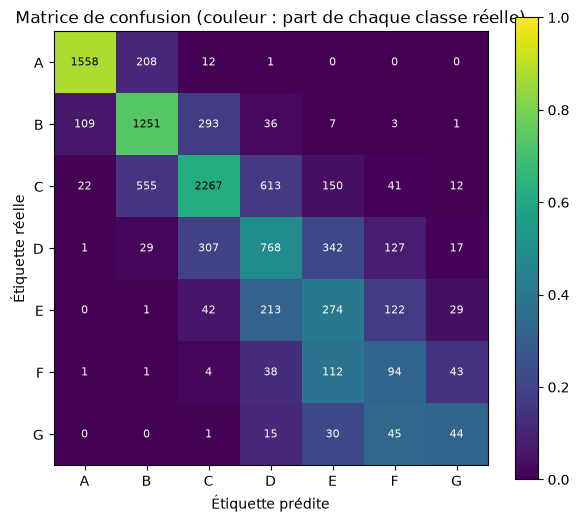

In [11]:
cm = confusion_matrix(test[ETIQ], pred, labels=ORDRE)
cm_norm = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(cm_norm, vmin=0, vmax=1)
ax.set_xticks(range(len(ORDRE)))
ax.set_xticklabels(ORDRE)
ax.set_yticks(range(len(ORDRE)))
ax.set_yticklabels(ORDRE)
ax.set_xlabel("Étiquette prédite")
ax.set_ylabel("Étiquette réelle")
for i in range(len(ORDRE)):
    for j in range(len(ORDRE)):
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center",
                color="white" if cm_norm[i, j] < 0.5 else "black", fontsize=8)
ax.set_title("Matrice de confusion (couleur : part de chaque classe réelle)")
fig.colorbar(image, ax=ax)
sauver(fig, "03_matrice_confusion")
plt.show()

### 5.3 Résultats par classe

In [22]:
rapport = classification_report(test[ETIQ], pred, labels=ORDRE, output_dict=True, zero_division=0)
par_classe = pd.DataFrame(rapport).T.loc[ORDRE + ["macro avg"]]
par_classe.columns = ["précision", "rappel", "f1", "effectif"]
print("précision : parmi les logements prédits dans la classe, part qui y est vraiment")
print("rappel    : parmi les logements réellement dans la classe, part retrouvée\n")
par_classe

précision : parmi les logements prédits dans la classe, part qui y est vraiment
rappel    : parmi les logements réellement dans la classe, part retrouvée



,précision,rappel,f1,effectif
A,0.921,0.876,0.898,"1,779.000"
B,0.612,0.736,0.668,"1,700.000"
C,0.775,0.619,0.688,"3,660.000"
D,0.456,0.483,0.469,"1,591.000"
E,0.299,0.402,0.343,681.000
F,0.218,0.321,0.259,293.000
G,0.301,0.326,0.313,135.000
macro avg,0.512,0.538,0.520,"9,839.000"


In [23]:
ecart = ecart_en_classes(test[ETIQ], pred)
print("Répartition des erreurs selon leur gravité :")
print(pd.Series(ecart).value_counts(normalize=True).sort_index().rename("part")
      .rename_axis("écart en classes").to_frame().round(4).to_string())

Répartition des erreurs selon leur gravité :
                  part
écart en classes      
0                0.636
1                0.301
2                0.052
3                0.009
4                0.002
5                0.000



### 5.4 Résultats par segment

In [24]:
test_eval = test.assign(pred=pred)


def resume_segment(g):
    return pd.Series({
        "lignes": len(g),
        "exactitude": accuracy_score(g[ETIQ], g["pred"]),
        "a_une_classe_pres": a_une_classe_pres(g[ETIQ], g["pred"]),
    })


print("Selon le jeu d'origine :")
display(test_eval.groupby("source_jeu")[[ETIQ, "pred"]].apply(resume_segment))

print("Selon la méthode de calcul du DPE :")
segments = test_eval.groupby("methode_application_dpe")[[ETIQ, "pred"]].apply(resume_segment)
segments.index = segments.index.astype(str).str[:70]
segments.sort_values("lignes", ascending=False)

Selon le jeu d'origine :


,lignes,exactitude,a_une_classe_pres
source_jeu,,,
existant,"9,096.000",0.610,0.932
neuf,743.000,0.957,0.991


Selon la méthode de calcul du DPE :


,lignes,exactitude,a_une_classe_pres
methode_application_dpe,,,
dpe appartement individuel,"6,056.000",0.607,0.926
dpe maison individuelle,"2,226.000",0.605,0.944
dpe appartement généré à partir des données DPE immeuble,701.000,0.709,0.967
dpe issu d'une étude thermique réglementaire RT2012 bâtiment : apparte,360.000,0.936,0.983
dpe immeuble collectif,219.000,0.589,0.927
dpe issu d'une étude thermique réglementaire RT2012 bâtiment : maison,212.000,0.976,1.000
dpe issu d'une étude thermique réglementaire RT2012 bâtiment : immeubl,32.000,0.938,0.969
dpe issu d'une étude energie environement réglementaire RE2020 bâtimen,30.000,1.000,1.000
dpe issu d'une étude energie environement réglementaire RE2020 bâtimen,2.000,1.000,1.000


### 5.5 Incertitude de l'évaluation
Dans le test, un gros immeuble compte pour des dizaines de lignes quasi identiques. Le score dépend donc de la composition du test. On mesure cette incertitude en **rééchantillonnant les adresses** du test avec remise (bootstrap par adresse), puis en recalculant le score : la fourchette obtenue indique de combien le résultat pourrait varier avec un autre échantillon d'adresses.

In [25]:
rng = np.random.default_rng(GRAINE)
blocs = list(test.groupby("groupe").indices.values())
y_vrai, y_pred = test[ETIQ].to_numpy(), np.asarray(pred)

tirages = {"f1_macro": [], "exactitude": []}
for _ in range(N_BOOTSTRAP):
    choix = rng.integers(0, len(blocs), len(blocs))
    idx = np.concatenate([blocs[k] for k in choix])
    tirages["f1_macro"].append(f1_score(y_vrai[idx], y_pred[idx], average="macro", labels=ORDRE, zero_division=0))
    tirages["exactitude"].append(accuracy_score(y_vrai[idx], y_pred[idx]))

intervalles = {k: np.percentile(v, [2.5, 97.5]) for k, v in tirages.items()}
for k, (bas, haut) in intervalles.items():
    print(f"{k} : {resume_test.iloc[0][k]:.3f}   intervalle à 95 % : [{bas:.3f} ; {haut:.3f}]")
print(f"\nPour comparaison, F1 macro en validation croisée sur le train : "
      f"{comparaison.loc[MEILLEUR, 'f1_macro']:.3f} (± {comparaison.loc[MEILLEUR, 'f1_macro_ecart_type']:.3f})")

f1_macro : 0.520   intervalle à 95 % : [0.501 ; 0.540]
exactitude : 0.636   intervalle à 95 % : [0.615 ; 0.656]

Pour comparaison, F1 macro en validation croisée sur le train : 0.519 (± 0.007)


## 6. Tests de variantes (validation croisée sur le train)
Chaque variante est évaluée avec les mêmes plis et les mêmes paramètres que le modèle retenu. La validation reste faite sur les **lignes d'origine** : seule change la façon d'entraîner. Pour tester une autre idée, ajouter une entrée au dictionnaire `variantes`.

Une différence plus petite que l'écart-type d'un pli à l'autre n'est pas une différence nette : dans ce cas on garde l'option la plus simple.

In [16]:
colonnes_copie = ["adresse_ban"] + [c for c in config.VARIABLES_CANDIDATES if c in train.columns] + [ETIQ, CONSO]


def nouveau_modele(num, cat):
    modele = clone(MODELES[MEILLEUR])
    modele.set_params(**meilleurs_parametres)
    modele.set_params(prep=tf.construire_preprocesseur(num, cat, pour=POUR[MEILLEUR]))
    return modele


def separer(variables):
    num = [v for v in variables if pd.api.types.is_numeric_dtype(train[v])]
    return num, [v for v in variables if v not in num]


def f1_en_validation_croisee(variables, dedoublonner=False):
    num, cat = separer(variables)
    scores = []
    for i_fit, i_val in plis:
        fit, val = train.iloc[i_fit], train.iloc[i_val]
        if dedoublonner:
            fit = fit.drop_duplicates(subset=colonnes_copie)
        modele = nouveau_modele(num, cat).fit(fit[variables], fit[ETIQ])
        scores.append(f1_score(val[ETIQ], modele.predict(val[variables]), average="macro",
                               labels=ORDRE, zero_division=0))
    return np.array(scores)


variantes = {"référence (variables retenues)": (VARIABLES, False),
             "copies exactes retirées de l'entraînement": (VARIABLES, True)}
if "annee_construction" in VARIABLES:
    variantes["sans annee_construction"] = ([v for v in VARIABLES if v != "annee_construction"], False)
elif "annee_construction" in train.columns:
    variantes["avec annee_construction"] = (VARIABLES + ["annee_construction"], False)

faibles = [v for v, raison in decisions.get("variables_retirees", {}).items()
           if raison.startswith("faible importance") and v in train.columns]
if faibles:
    variantes["avec les variables de faible importance"] = (VARIABLES + faibles, False)

lignes = {}
for nom, (variables, dedoublonner) in variantes.items():
    scores = f1_en_validation_croisee(variables, dedoublonner)
    lignes[nom] = {"f1_macro": scores.mean(), "ecart_type_entre_plis": scores.std()}
    print(f"{nom} : terminé")

sensibilite = pd.DataFrame(lignes).T
sensibilite["difference_avec_reference"] = sensibilite["f1_macro"] - sensibilite.iloc[0]["f1_macro"]
sensibilite

référence (variables retenues) : terminé
copies exactes retirées de l'entraînement : terminé
sans annee_construction : terminé
avec les variables de faible importance : terminé


,f1_macro,ecart_type_entre_plis,difference_avec_reference
référence (variables retenues),0.529,0.004,0.000
copies exactes retirées de l'entraînement,0.529,0.004,0.000
sans annee_construction,0.530,0.007,0.000
avec les variables de faible importance,0.531,0.007,0.001





## 7. Sauvegarde

In [17]:
config.DOSSIER_MODELES.mkdir(parents=True, exist_ok=True)
chemin_modele = config.DOSSIER_MODELES / "modele_classification.joblib"
joblib.dump(modele_final, chemin_modele)

# Contrôle : le pipeline rechargé donne exactement les mêmes prédictions.
recharge = joblib.load(chemin_modele)
pred = modele_final.predict(test[VARIABLES])   # recalcule les prédictions du test
assert (recharge.predict(test[VARIABLES]) == pred).all()

bilan = {
    "modele": MEILLEUR,
    "parametres": {k: (v if isinstance(v, (int, float, str)) else str(v)) for k, v in meilleurs_parametres.items()},
    "variables": VARIABLES,
    "validation_croisee_train": comparaison.loc[MEILLEUR].to_dict(),
    "test": resume_test.iloc[0].to_dict(),
    "test_intervalle_95": {k: [float(b), float(h)] for k, (b, h) in intervalles.items()},
    "test_reference": resume_test.loc[BASE].to_dict(),
}
with open(config.DOSSIER_MODELES / "metriques_classification.json", "w", encoding="utf-8") as f:
    json.dump(bilan, f, ensure_ascii=False, indent=2)

comparaison.to_csv(config.DATA_TRAITE / "comparaison_modeles_classification.csv")
sensibilite.to_csv(config.DATA_TRAITE / "sensibilite_classification.csv")
print("Fichiers écrits :")
for chemin in [chemin_modele, config.DOSSIER_MODELES / "metriques_classification.json",
               config.DATA_TRAITE / "comparaison_modeles_classification.csv",
               config.DATA_TRAITE / "sensibilite_classification.csv"]:
    print(" -", chemin.relative_to(config.RACINE))

Fichiers écrits :
 - models\modele_classification.joblib
 - models\metriques_classification.json
 - data\processed\comparaison_modeles_classification.csv
 - data\processed\sensibilite_classification.csv
